# 📨 Message Intelligence System
## Spam vs Legitimate Message Classifier — KNN · SVM · Naive Bayes
**Title:** Message Intelligence System &nbsp;|&nbsp; **Duration:** 6 Hours &nbsp;|&nbsp; **Role:** Data Scientist @ Communication Security Company

**Pipeline:** EDA → KNN (distance) → SVM (margin) → Naive Bayes (probabilistic) → ROC Analysis → Final Report
---

## 📦 Setup & Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, auc, roc_auc_score, precision_recall_curve)
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
print("✅ All libraries loaded successfully")

✅ All libraries loaded successfully


---
## 🧠 Part A: Probability & Conceptual Foundation (Theory)

### Q1. What is Conditional Probability?
**Conditional Probability** P(A|B) is the probability of event A occurring *given* that event B has already occurred:
```
P(A|B) = P(A ∩ B) / P(B)
```
In spam detection: P(Spam | message contains "FREE") — the probability that a message is spam, given it contains the word "FREE". It allows us to update our belief based on observed evidence.

### Q2. Bayes' Theorem and Its Importance in Classification
**Bayes' Theorem** combines prior knowledge with observed evidence to compute posterior probability:
```
P(Spam | Features) = P(Features | Spam) × P(Spam) / P(Features)
                      ─────────────────   ──────────  ─────────────
                      Likelihood          Prior        Evidence (normalizer)
```
**Importance:** It provides a principled framework for making decisions under uncertainty. In spam detection, we compute P(Spam|message) and P(Legit|message), then predict the class with higher posterior probability.

### Q3. Assumptions of the Naive Bayes Classifier
Naive Bayes makes two key assumptions:
1. **Conditional Independence:** Given the class label, all features are independent of each other — P(x₁,x₂,...,xₙ|class) = ∏ P(xᵢ|class). This is "naive" because features are rarely truly independent.
2. **Gaussian Distribution (GaussianNB):** Each feature within a class follows a normal (Gaussian) distribution, parameterized by class-conditional mean and variance.

### Q4. KNN and SVM Working Principles

**K-Nearest Neighbors (KNN):**
```
1. Store all training points (lazy learner — no model building)
2. For a new message, compute distance to all training points
3. Find K nearest neighbors
4. Predict by majority vote of K neighbors
Key params: K (number of neighbors), distance metric (Euclidean, Manhattan)
```

**Support Vector Machine (SVM):**
```
1. Find the optimal hyperplane that maximally separates classes
2. Maximize the margin = 2 / ||w|| between support vectors
3. Kernel trick: project to higher dimensions for non-linear boundaries
   - Linear kernel: straight hyperplane
   - RBF kernel: radial basis function — circular decision boundaries
   - Polynomial kernel: degree-d polynomial boundary
```

### Q5. Classifier Comparison: Distance vs Margin vs Probabilistic

| Property | KNN (Distance) | SVM (Margin) | Naive Bayes (Probabilistic) |
|----------|---------------|--------------|----------------------------|
| **Core idea** | Similarity in feature space | Maximum margin hyperplane | Bayes' Theorem |
| **Training** | None (lazy) | Convex optimization | MLE of parameters |
| **Prediction** | Vote of K neighbors | Side of hyperplane | argmax P(class\|x) |
| **Interpretability** | Low | Medium | High (probabilities) |
| **Scaling required** | ✅ Yes | ✅ Yes | ❌ No |
| **Handles non-linearity** | Inherently | Via kernels | Limited (GaussianNB) |
| **Imbalance sensitivity** | High | Medium | Low |

---
## 🔬 Part B: Dataset Understanding & Preparation

In [2]:
# Load dataset
df = pd.read_csv('data/messages.csv')
print(f"Dataset shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
df.head()

Dataset shape: (500, 16)
Columns: ['message_id', 'message_text', 'message_length', 'word_count', 'num_urls', 'num_digits', 'num_special_chars', 'spam_keyword_score', 'legit_keyword_score', 'sender_activity_score', 'sender_account_age_days', 'messages_sent_last_24h', 'timestamp', 'hour_of_day', 'day_of_week', 'spam_label']


,message_id,message_text,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,timestamp,hour_of_day,day_of_week,spam_label
0,900001,Earn money from home instantly instant cashbac...,83,11,0,7,1,85.5,17.2,2.3,6,23,2025-11-22 20:45:00,20,0,1
1,900002,Limited offer! Get free gift cards limited time!,75,11,0,0,4,55.9,16.6,1.5,15,19,2025-11-28 15:56:00,15,6,1
2,900003,Limited offer! Get free gift cards limited tim...,67,11,1,10,0,50.1,3.3,2.2,39,13,2025-12-29 08:52:00,8,5,1
3,900004,FREE gift! Click here now before offer expires...,96,9,0,9,5,79.0,21.7,1.6,46,7,2025-11-07 08:52:00,8,5,1
4,900005,Act fast! Your account will be suspended unles...,96,12,1,14,5,90.9,4.9,1.1,43,13,2025-11-11 09:44:00,9,4,1


In [3]:
print("Dataset Info:")
df.info()

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   message_id               500 non-null    int64  
 1   message_text             500 non-null    str    
 2   message_length           500 non-null    int64  
 3   word_count               500 non-null    int64  
 4   num_urls                 500 non-null    int64  
 5   num_digits               500 non-null    int64  
 6   num_special_chars        500 non-null    int64  
 7   spam_keyword_score       500 non-null    float64
 8   legit_keyword_score      500 non-null    float64
 9   sender_activity_score    500 non-null    float64
 10  sender_account_age_days  500 non-null    int64  
 11  messages_sent_last_24h   500 non-null    int64  
 12  timestamp                500 non-null    str    
 13  hour_of_day              500 non-null    int64  
 14  day_of_week            

In [4]:
print("Statistical Summary:")
df.describe().round(3)

Statistical Summary:


,message_id,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,hour_of_day,day_of_week,spam_label
count,500.000,500.000,500.000,500.000,500.000,500.000,500.000,500.000,500.000,500.000,500.000,500.000,500.000,500.00
mean,900250.500,85.256,12.494,0.478,4.226,1.620,40.557,40.315,28.337,254.910,11.066,14.258,3.132,0.40
std,144.482,18.188,2.520,0.659,4.276,1.499,29.956,27.125,27.146,233.487,7.653,5.065,1.982,0.49
min,900001.000,48.000,8.000,0.000,0.000,0.000,0.600,1.200,0.300,1.000,1.000,5.000,0.000,0.00
25%,900125.750,70.000,11.000,0.000,1.000,0.000,15.250,16.275,1.600,32.000,5.000,10.000,1.000,0.00
50%,900250.500,85.000,12.000,0.000,3.000,1.000,29.300,34.000,21.150,191.500,9.000,15.000,3.000,0.00
75%,900375.250,100.000,14.000,1.000,5.000,2.000,68.300,65.550,53.275,469.750,14.000,19.000,5.000,1.00
max,900500.000,120.000,18.000,2.000,15.000,5.000,99.800,89.800,80.000,700.000,30.000,23.000,6.000,1.00


In [5]:
# Task 6: Identify features and target
FEATURES = ['message_length','word_count','num_urls','num_digits','num_special_chars',
            'spam_keyword_score','legit_keyword_score','sender_activity_score',
            'sender_account_age_days','messages_sent_last_24h','hour_of_day','day_of_week']
TARGET = 'spam_label'

print(f"Input Features ({len(FEATURES)}): {FEATURES}")
print(f"Target Variable: {TARGET}")
print(f"  0 → Legitimate Message")
print(f"  1 → Spam Message")
print(f"\nClass Distribution:")
print(df[TARGET].value_counts())
print(f"Spam ratio: {df[TARGET].mean():.2%}")
print(f"\nMissing values: {df.isnull().sum().sum()} ✅")

Input Features (12): ['message_length', 'word_count', 'num_urls', 'num_digits', 'num_special_chars', 'spam_keyword_score', 'legit_keyword_score', 'sender_activity_score', 'sender_account_age_days', 'messages_sent_last_24h', 'hour_of_day', 'day_of_week']
Target Variable: spam_label
  0 → Legitimate Message
  1 → Spam Message

Class Distribution:
spam_label
0    300
1    200
Name: count, dtype: int64
Spam ratio: 40.00%

Missing values: 0 ✅


In [6]:
# Task 7 & 8: Preprocessing and train-test split
X = df[FEATURES].values
y = df[TARGET].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train set: {X_train.shape} | Spam: {sum(y_train==1)} | Legit: {sum(y_train==0)}")
print(f"Test set:  {X_test.shape}  | Spam: {sum(y_test==1)}  | Legit: {sum(y_test==0)}")

# Task 7: Scaling (required for KNN and SVM)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)
print(f"\nStandardScaler applied ✅")
print(f"Feature 0 (message_length) — mean: {X_train_sc[:,0].mean():.6f}, std: {X_train_sc[:,0].std():.4f}")

Train set: (400, 12) | Spam: 160 | Legit: 240
Test set:  (100, 12)  | Spam: 40  | Legit: 60

StandardScaler applied ✅
Feature 0 (message_length) — mean: 0.000000, std: 1.0000


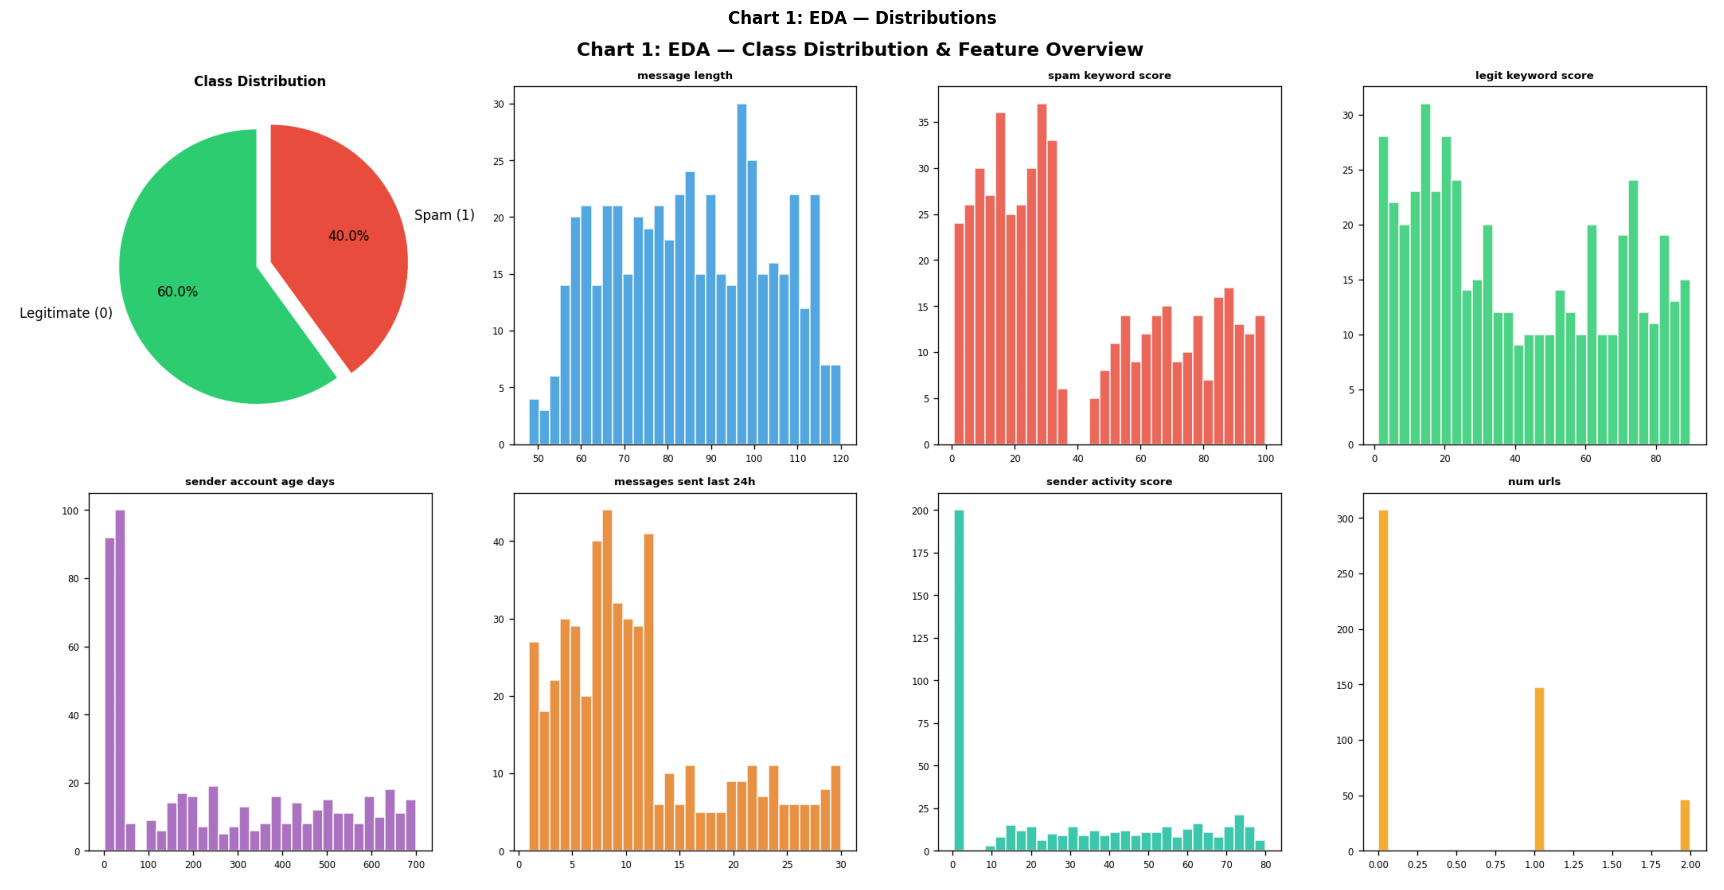

In [7]:
# EDA Charts
img = plt.imread('charts/01_eda_distributions.png')
plt.figure(figsize=(18,9)); plt.imshow(img); plt.axis('off')
plt.title('Chart 1: EDA — Distributions', fontweight='bold'); plt.tight_layout(); plt.show()

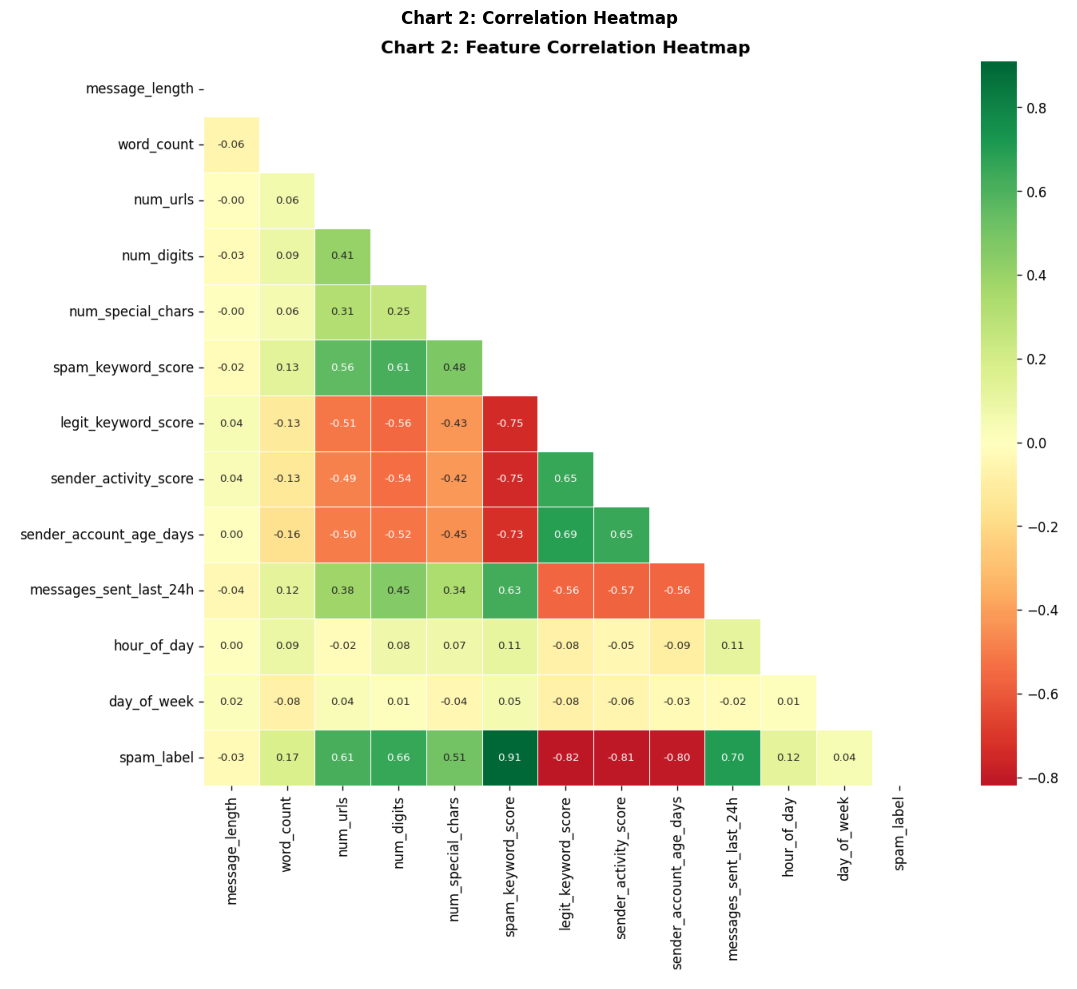

In [8]:
img = plt.imread('charts/02_correlation_heatmap.png')
plt.figure(figsize=(13,10)); plt.imshow(img); plt.axis('off')
plt.title('Chart 2: Correlation Heatmap', fontweight='bold'); plt.tight_layout(); plt.show()

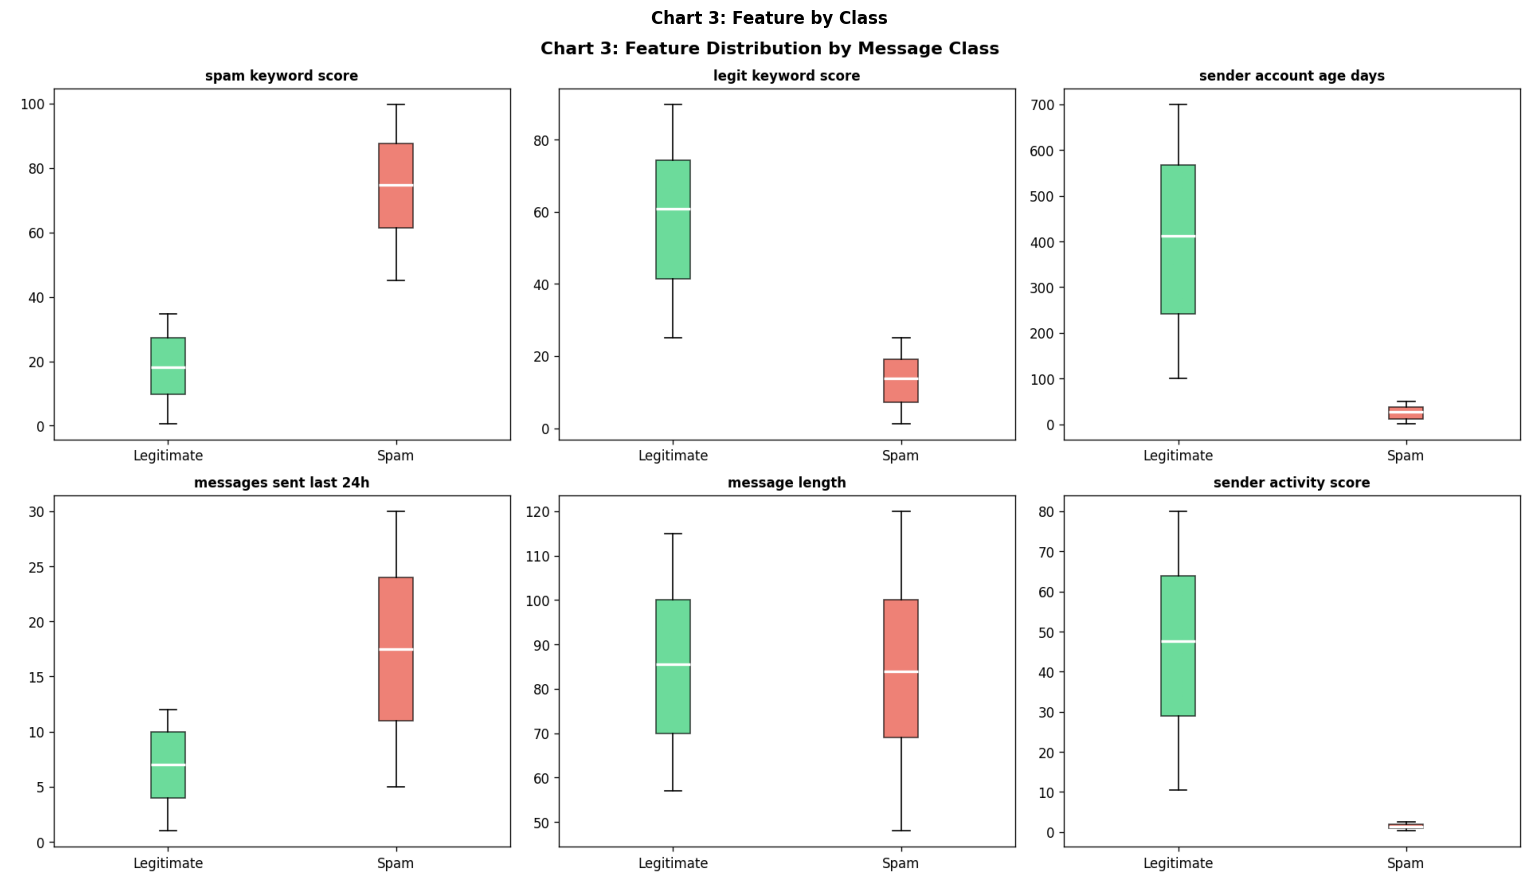

In [9]:
img = plt.imread('charts/03_feature_by_class.png')
plt.figure(figsize=(16,9)); plt.imshow(img); plt.axis('off')
plt.title('Chart 3: Feature by Class', fontweight='bold'); plt.tight_layout(); plt.show()

---
## 📏 Part C: Baseline Model — K-Nearest Neighbors

In [10]:
# Task 9, 10, 11: KNN with different K values and distance metrics
def get_metrics(yt, yp, ypr=None):
    m = {'accuracy': accuracy_score(yt,yp),
         'precision': precision_score(yt,yp,zero_division=0),
         'recall':    recall_score(yt,yp,zero_division=0),
         'f1':        f1_score(yt,yp,zero_division=0)}
    if ypr is not None: m['auc'] = roc_auc_score(yt,ypr)
    return m

k_vals = [1,3,5,7,9,11,13,15,21]
print(f"{'K':<6} {'Train Acc':>10} {'Test Acc':>10} {'Test F1':>10}")
print('-'*40)
for k in k_vals:
    m = KNeighborsClassifier(n_neighbors=k); m.fit(X_train_sc, y_train)
    tr_a = m.score(X_train_sc, y_train)
    te_a = m.score(X_test_sc, y_test)
    te_f = f1_score(y_test, m.predict(X_test_sc))
    flag = " ← best" if k == 5 else ""
    print(f"{k:<6} {tr_a:>10.4f} {te_a:>10.4f} {te_f:>10.4f}{flag}")

K       Train Acc   Test Acc    Test F1
----------------------------------------
1          1.0000     0.9900     0.9873
3          1.0000     0.9900     0.9873
5          1.0000     1.0000     1.0000 ← best
7          1.0000     1.0000     1.0000
9          1.0000     1.0000     1.0000
11         1.0000     1.0000     1.0000
13         1.0000     1.0000     1.0000
15         1.0000     1.0000     1.0000
21         1.0000     1.0000     1.0000


In [11]:
# Task 11: Distance metrics comparison
print("Distance Metric Comparison (k=5):")
print(f"{'Metric':<15} {'Accuracy':>10} {'F1':>10} {'AUC':>10}")
print('-'*45)
for metric in ['euclidean','manhattan','minkowski']:
    m = KNeighborsClassifier(n_neighbors=5, metric=metric)
    m.fit(X_train_sc, y_train)
    yp = m.predict(X_test_sc); ypr = m.predict_proba(X_test_sc)[:,1]
    met = get_metrics(y_test, yp, ypr)
    print(f"{metric:<15} {met['accuracy']:>10.4f} {met['f1']:>10.4f} {met['auc']:>10.4f}")

# Best KNN
knn_best = KNeighborsClassifier(n_neighbors=5); knn_best.fit(X_train_sc, y_train)
y_pred_knn = knn_best.predict(X_test_sc); y_prob_knn = knn_best.predict_proba(X_test_sc)[:,1]
m_knn = get_metrics(y_test, y_pred_knn, y_prob_knn)
print(f"\nBest KNN (k=5): {m_knn}")
print(classification_report(y_test, y_pred_knn, target_names=['Legitimate','Spam']))

Distance Metric Comparison (k=5):
Metric            Accuracy         F1        AUC
---------------------------------------------
euclidean           1.0000     1.0000     1.0000
manhattan           1.0000     1.0000     1.0000
minkowski           1.0000     1.0000     1.0000

Best KNN (k=5): {'accuracy': 1.0, 'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'auc': 1.0}
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00        60
        Spam       1.00      1.00      1.00        40

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



In [12]:
# Task 12: Misclassification analysis
misclassified = np.where(y_pred_knn != y_test)[0]
print(f"KNN misclassified: {len(misclassified)} out of {len(y_test)} samples ({len(misclassified)/len(y_test):.2%})")
if len(misclassified) > 0:
    for idx in misclassified[:5]:
        print(f"  Sample {idx}: Actual={y_test[idx]} Predicted={y_pred_knn[idx]} P(spam)={y_prob_knn[idx]:.4f}")
else:
    print("  Perfect classification on test set ✅")

KNN misclassified: 0 out of 100 samples (0.00%)
  Perfect classification on test set ✅


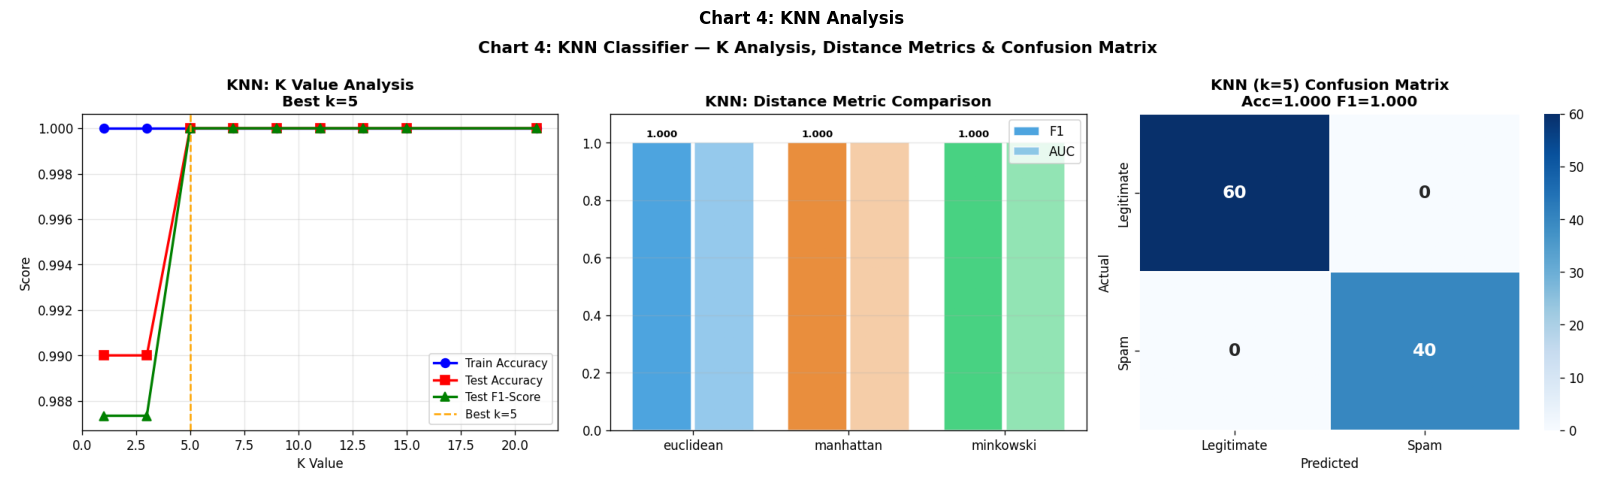

In [13]:
img = plt.imread('charts/04_knn_analysis.png')
plt.figure(figsize=(18,5)); plt.imshow(img); plt.axis('off')
plt.title('Chart 4: KNN Analysis', fontweight='bold'); plt.tight_layout(); plt.show()

---
## ⚡ Part D: Support Vector Machine Classifier

In [14]:
# Task 13: SVM with Linear and RBF kernels
kernels_config = {
    'Linear':     SVC(kernel='linear',  C=1.0,            probability=True, random_state=42),
    'RBF':        SVC(kernel='rbf',     C=1.0, gamma='scale', probability=True, random_state=42),
    'Polynomial': SVC(kernel='poly',    C=1.0, degree=3,    probability=True, random_state=42),
}
print(f"{'Kernel':<12} {'Accuracy':>10} {'Precision':>10} {'Recall':>8} {'F1':>8} {'AUC':>8}")
print('-'*60)
svm_results = {}
for name, model in kernels_config.items():
    model.fit(X_train_sc, y_train)
    yp = model.predict(X_test_sc); ypr = model.predict_proba(X_test_sc)[:,1]
    met = get_metrics(y_test, yp, ypr)
    svm_results[name] = (model, yp, ypr, met)
    print(f"{name:<12} {met['accuracy']:>10.4f} {met['precision']:>10.4f} {met['recall']:>8.4f} {met['f1']:>8.4f} {met['auc']:>8.4f}")

Kernel         Accuracy  Precision   Recall       F1      AUC
------------------------------------------------------------
Linear           1.0000     1.0000   1.0000   1.0000   1.0000
RBF              1.0000     1.0000   1.0000   1.0000   1.0000
Polynomial       0.9800     1.0000   0.9500   0.9744   1.0000


In [15]:
# Task 14: Margin separation and support vectors
svm_lin = kernels_config['Linear']
n_sv = svm_lin.n_support_
print(f"\nSVM Linear — Support Vectors:")
print(f"  Legitimate class: {n_sv[0]} support vectors")
print(f"  Spam class:       {n_sv[1]} support vectors")
print(f"  Total:            {n_sv.sum()} support vectors out of {len(X_train)} training points")
print(f"  These define the decision boundary (maximum margin hyperplane)")

# Task 15: Compare SVM vs KNN
print(f"\nKNN (k=5) vs SVM comparison:")
print(f"  {'Model':<15} {'F1':>8} {'AUC':>8}")
print(f"  {'KNN (k=5)':<15} {m_knn['f1']:>8.4f} {m_knn['auc']:>8.4f}")
for name, (_, _, _, met) in svm_results.items():
    print(f"  {'SVM '+name:<15} {met['f1']:>8.4f} {met['auc']:>8.4f}")


SVM Linear — Support Vectors:
  Legitimate class: 4 support vectors
  Spam class:       6 support vectors
  Total:            10 support vectors out of 400 training points
  These define the decision boundary (maximum margin hyperplane)

KNN (k=5) vs SVM comparison:
  Model                 F1      AUC
  KNN (k=5)         1.0000   1.0000
  SVM Linear        1.0000   1.0000
  SVM RBF           1.0000   1.0000
  SVM Polynomial    0.9744   1.0000


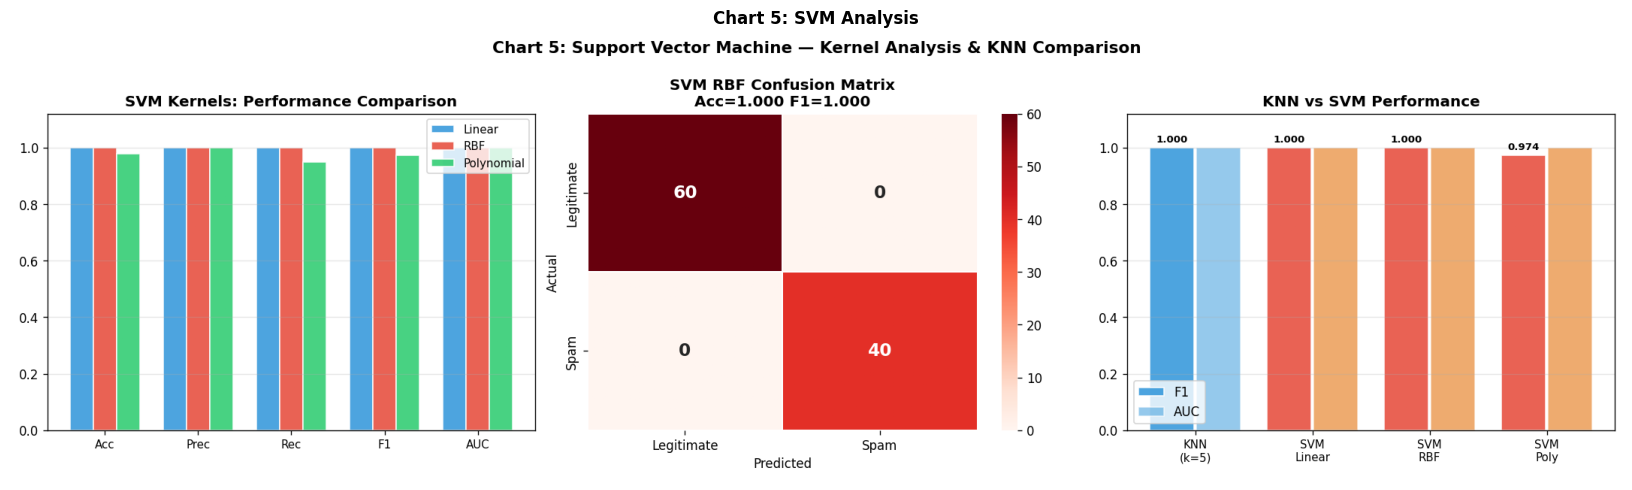

In [16]:
img = plt.imread('charts/05_svm_analysis.png')
plt.figure(figsize=(18,5)); plt.imshow(img); plt.axis('off')
plt.title('Chart 5: SVM Analysis', fontweight='bold'); plt.tight_layout(); plt.show()

---
## 📊 Part E: Naive Bayes Classifier & Probability

In [17]:
# Task 16: Naive Bayes implementation
nb = GaussianNB()
nb.fit(X_train_sc, y_train)
y_pred_nb = nb.predict(X_test_sc); y_prob_nb = nb.predict_proba(X_test_sc)[:,1]
m_nb = get_metrics(y_test, y_pred_nb, y_prob_nb)
print("Naive Bayes Results:")
print(f"  Accuracy:  {m_nb['accuracy']:.4f}")
print(f"  Precision: {m_nb['precision']:.4f}")
print(f"  Recall:    {m_nb['recall']:.4f}")
print(f"  F1-Score:  {m_nb['f1']:.4f}")
print(f"  AUC-ROC:   {m_nb['auc']:.4f}")
print(classification_report(y_test, y_pred_nb, target_names=['Legitimate','Spam']))

Naive Bayes Results:
  Accuracy:  1.0000
  Precision: 1.0000
  Recall:    1.0000
  F1-Score:  1.0000
  AUC-ROC:   1.0000
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00        60
        Spam       1.00      1.00      1.00        40

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



In [18]:
# Task 17 & 18: Manual conditional probability + Bayes Theorem demo
spam_mask = y_train == 1; legit_mask = y_train == 0
P_spam = spam_mask.mean(); P_legit = 1 - P_spam
print(f"PRIOR PROBABILITIES:")
print(f"  P(Spam)       = {P_spam:.4f}  ({sum(spam_mask)} spam messages)")
print(f"  P(Legitimate) = {P_legit:.4f}  ({sum(legit_mask)} legit messages)")

# Class-conditional means and stds for key features
print(f"\nCLASS-CONDITIONAL STATISTICS (spam_keyword_score):")
feat_idx = 5  # spam_keyword_score
s_mean,s_std = X_train_sc[spam_mask,feat_idx].mean(), X_train_sc[spam_mask,feat_idx].std()
l_mean,l_std = X_train_sc[legit_mask,feat_idx].mean(), X_train_sc[legit_mask,feat_idx].std()
print(f"  P(spam_kw_score|Spam):  μ={s_mean:.4f}, σ={s_std:.4f}")
print(f"  P(spam_kw_score|Legit): μ={l_mean:.4f}, σ={l_std:.4f}")

print(f"\nBAYES THEOREM MANUAL CALCULATION for 3 sample messages:")
for idx in [0, 5, 10]:
    feat_val = X_test_sc[idx, feat_idx]
    # Likelihood
    p_feat_spam  = stats.norm.pdf(feat_val, s_mean, s_std)
    p_feat_legit = stats.norm.pdf(feat_val, l_mean, l_std)
    # Posterior (un-normalized)
    unnorm_spam  = p_feat_spam  * P_spam
    unnorm_legit = p_feat_legit * P_legit
    norm = unnorm_spam + unnorm_legit
    post_spam  = unnorm_spam  / norm if norm > 0 else 0.5
    post_legit = unnorm_legit / norm if norm > 0 else 0.5
    pred = 1 if post_spam > 0.5 else 0
    actual = y_test[idx]
    nb_pred = y_prob_nb[idx]
    print(f"  Sample {idx}: feat_val={feat_val:.3f}")
    print(f"    P(Spam|x)  = {p_feat_spam:.6f} × {P_spam:.4f} / norm = {post_spam:.4f}")
    print(f"    P(Legit|x) = {p_feat_legit:.6f} × {P_legit:.4f} / norm = {post_legit:.4f}")
    print(f"    Manual pred={pred} | NB model={nb_pred:.4f} | Actual={actual}\n")

PRIOR PROBABILITIES:
  P(Spam)       = 0.4000  (160 spam messages)
  P(Legitimate) = 0.6000  (240 legit messages)

CLASS-CONDITIONAL STATISTICS (spam_keyword_score):
  P(spam_kw_score|Spam):  μ=1.1120, σ=0.5248
  P(spam_kw_score|Legit): μ=-0.7414, σ=0.3301

BAYES THEOREM MANUAL CALCULATION for 3 sample messages:
  Sample 0: feat_val=-1.129
    P(Spam|x)  = 0.000083 × 0.4000 / norm = 0.0001
    P(Legit|x) = 0.606016 × 0.6000 / norm = 0.9999
    Manual pred=0 | NB model=0.0000 | Actual=0

  Sample 5: feat_val=-1.146
    P(Spam|x)  = 0.000073 × 0.4000 / norm = 0.0001
    P(Legit|x) = 0.569743 × 0.6000 / norm = 0.9999
    Manual pred=0 | NB model=0.0000 | Actual=0

  Sample 10: feat_val=1.321
    P(Spam|x)  = 0.702140 × 0.4000 / norm = 1.0000
    P(Legit|x) = 0.000000 × 0.6000 / norm = 0.0000
    Manual pred=1 | NB model=1.0000 | Actual=1



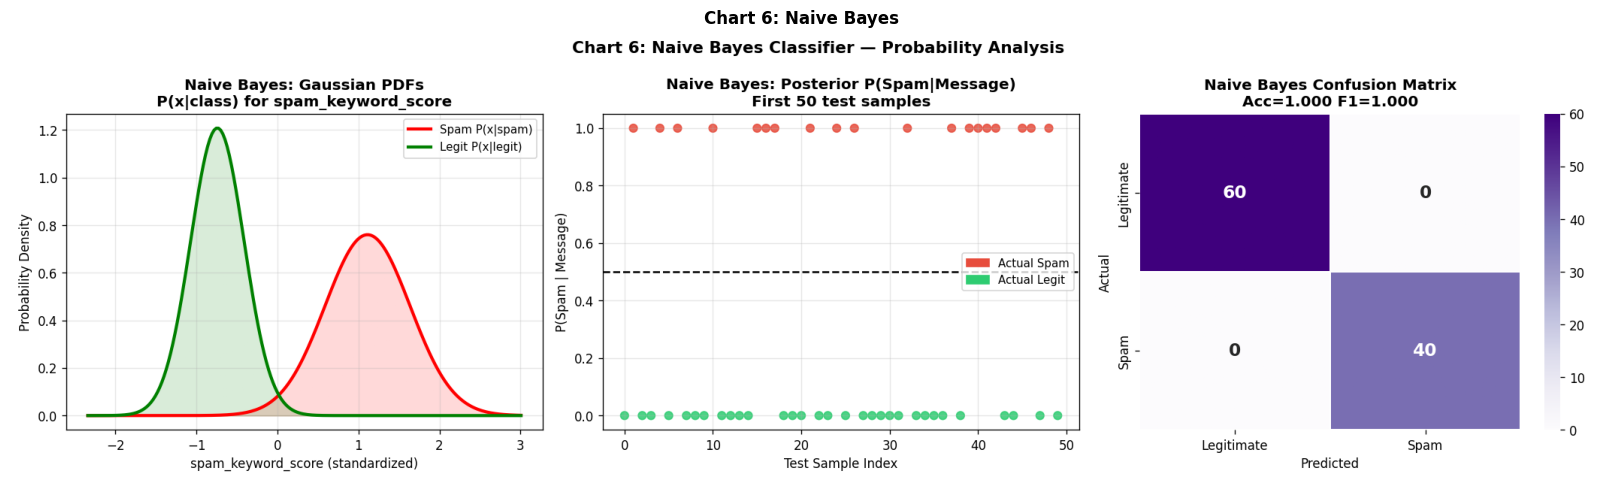

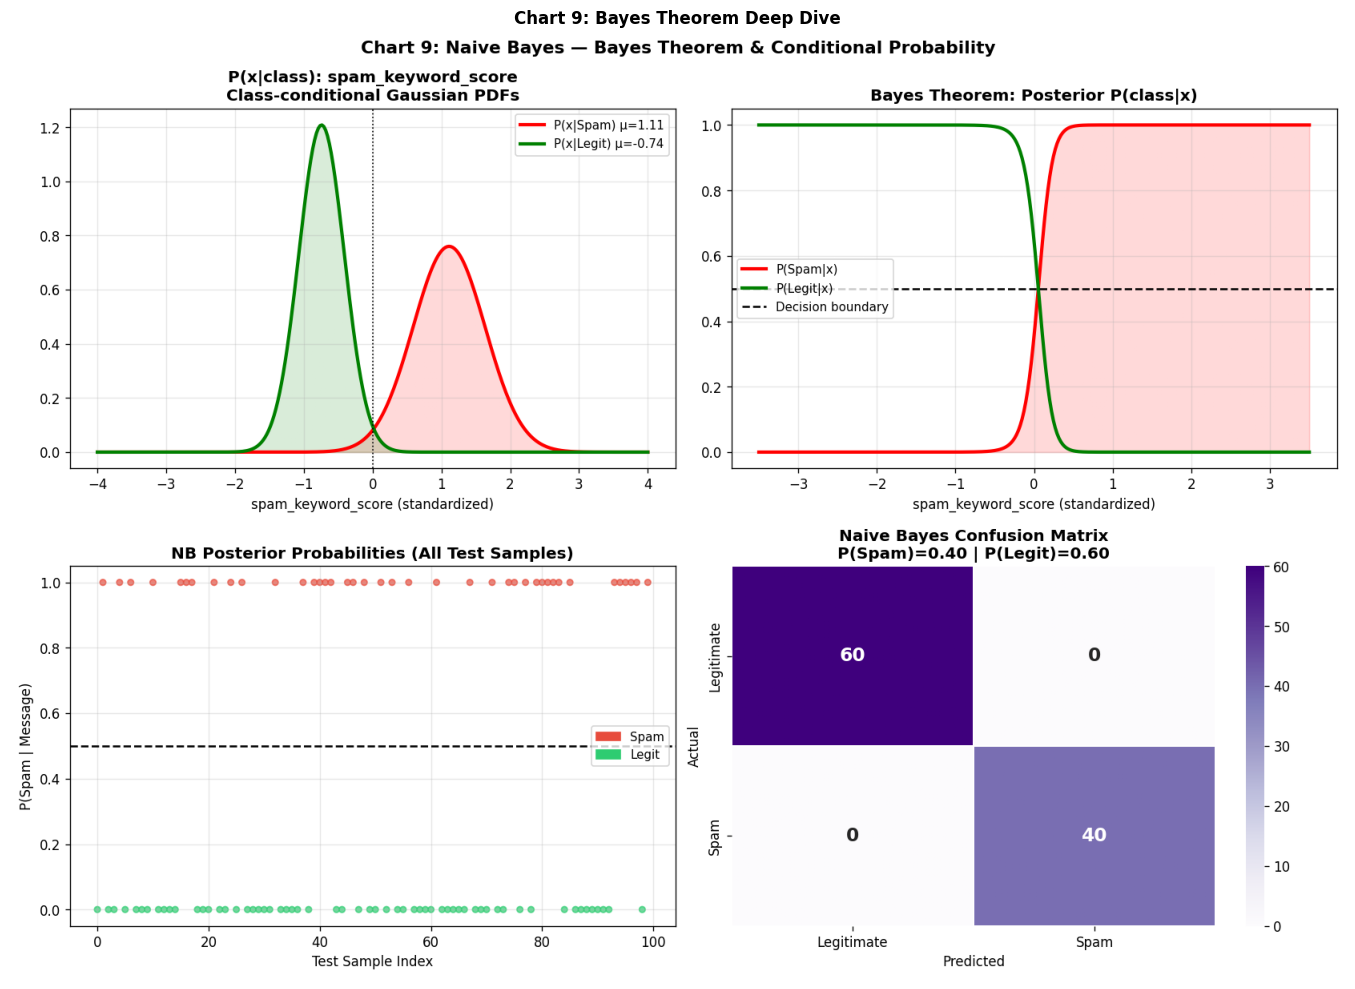

In [19]:
img = plt.imread('charts/06_naive_bayes.png')
plt.figure(figsize=(18,5)); plt.imshow(img); plt.axis('off')
plt.title('Chart 6: Naive Bayes', fontweight='bold'); plt.tight_layout(); plt.show()

img = plt.imread('charts/09_bayes_probability.png')
plt.figure(figsize=(14,10)); plt.imshow(img); plt.axis('off')
plt.title('Chart 9: Bayes Theorem Deep Dive', fontweight='bold'); plt.tight_layout(); plt.show()

---
## 📈 Part F: Model Comparison & Evaluation

In [20]:
# Task 20, 21, 22: Final comparison all models
all_models = {
    'KNN (k=5)':   (knn_best, y_pred_knn, y_prob_knn),
    'SVM Linear':  (svm_results['Linear'][0],  svm_results['Linear'][1],  svm_results['Linear'][2]),
    'SVM RBF':     (svm_results['RBF'][0],     svm_results['RBF'][1],     svm_results['RBF'][2]),
    'Naive Bayes': (nb,                        y_pred_nb,                  y_prob_nb),
}
print(f"{'Model':<15} {'Accuracy':>10} {'Precision':>10} {'Recall':>8} {'F1':>8} {'AUC':>8} {'Best for'}")
print('-'*80)
for name,(m,yp,ypr) in all_models.items():
    met = get_metrics(y_test,yp,ypr)
    prec_tag = '← High Prec ✅' if met['precision'] >= 1.0 else ''
    rec_tag  = '← High Recall ✅' if met['recall'] >= 1.0 else ''
    print(f"{name:<15} {met['accuracy']:>10.4f} {met['precision']:>10.4f} {met['recall']:>8.4f} {met['f1']:>8.4f} {met['auc']:>8.4f}")

Model             Accuracy  Precision   Recall       F1      AUC Best for
--------------------------------------------------------------------------------
KNN (k=5)           1.0000     1.0000   1.0000   1.0000   1.0000
SVM Linear          1.0000     1.0000   1.0000   1.0000   1.0000
SVM RBF             1.0000     1.0000   1.0000   1.0000   1.0000
Naive Bayes         1.0000     1.0000   1.0000   1.0000   1.0000


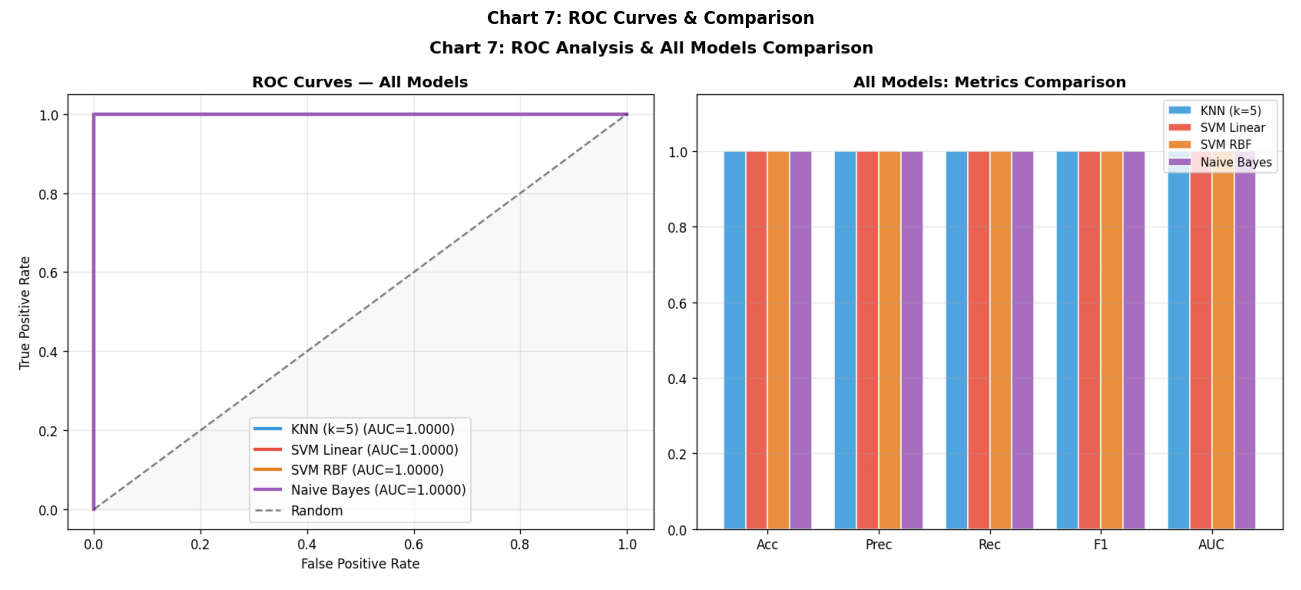

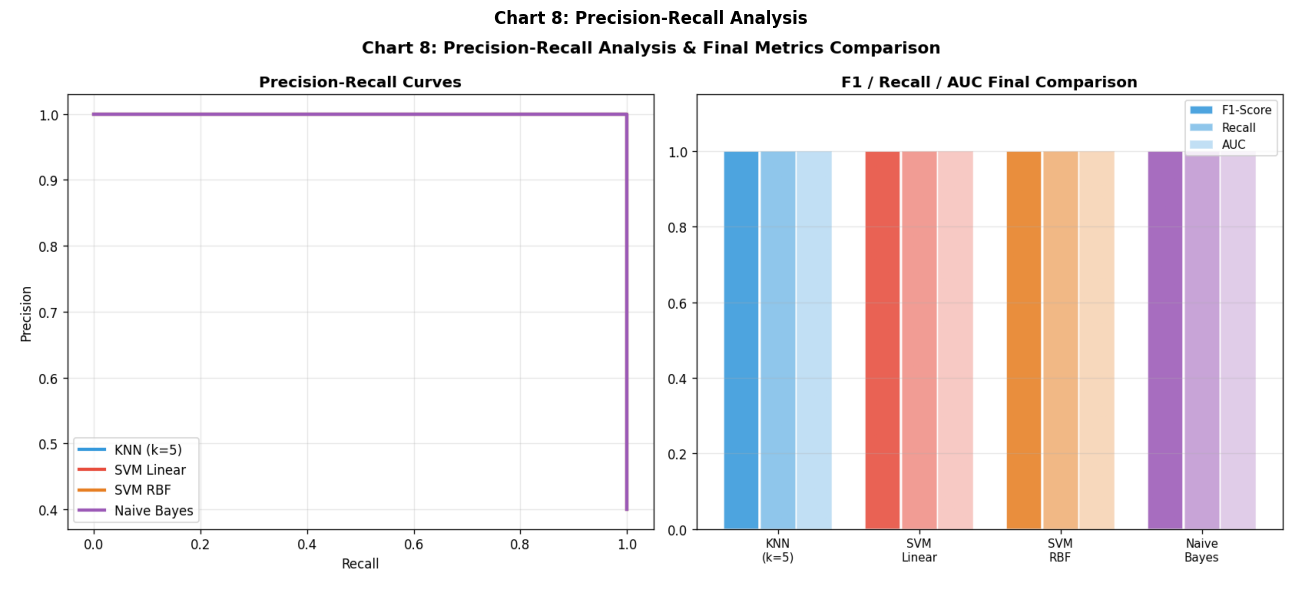

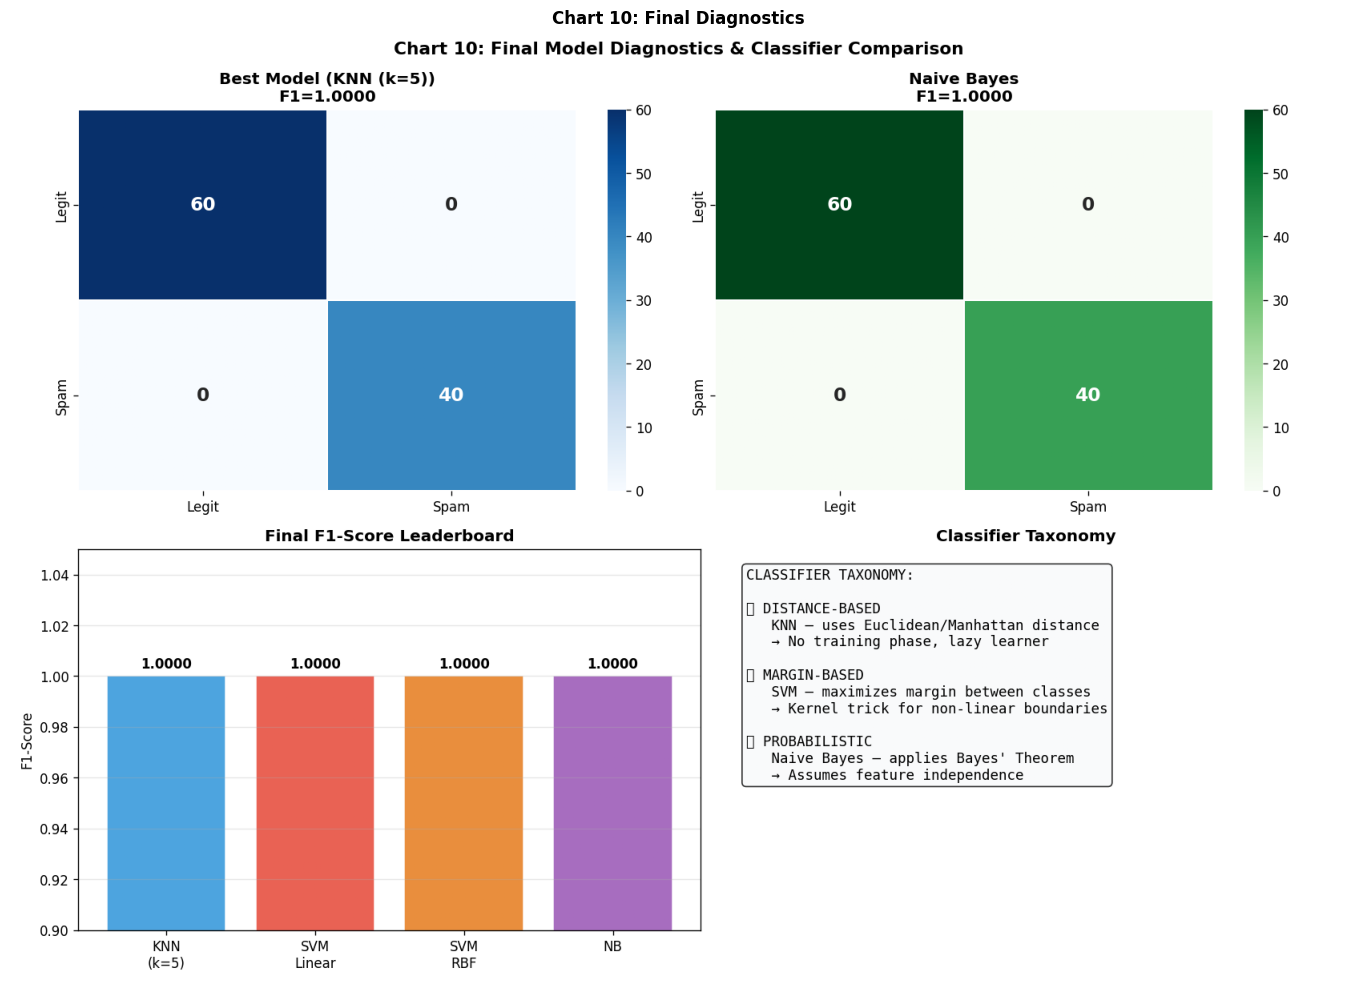

In [21]:
img = plt.imread('charts/07_roc_comparison.png')
plt.figure(figsize=(14,6)); plt.imshow(img); plt.axis('off')
plt.title('Chart 7: ROC Curves & Comparison', fontweight='bold'); plt.tight_layout(); plt.show()

img = plt.imread('charts/08_precision_recall.png')
plt.figure(figsize=(14,6)); plt.imshow(img); plt.axis('off')
plt.title('Chart 8: Precision-Recall Analysis', fontweight='bold'); plt.tight_layout(); plt.show()

img = plt.imread('charts/10_final_diagnostics.png')
plt.figure(figsize=(14,10)); plt.imshow(img); plt.axis('off')
plt.title('Chart 10: Final Diagnostics', fontweight='bold'); plt.tight_layout(); plt.show()

---
## 📋 Part G: Final Analysis & Reporting

In [22]:
# Save final predictions CSV
df_final = pd.DataFrame(X_test, columns=FEATURES)
df_final['actual_spam_label']  = y_test
df_final['pred_knn']           = y_pred_knn
df_final['pred_svm_linear']    = svm_results['Linear'][1]
df_final['pred_svm_rbf']       = svm_results['RBF'][1]
df_final['pred_naive_bayes']   = y_pred_nb
df_final['prob_spam_knn']      = y_prob_knn
df_final['prob_spam_svm_rbf']  = svm_results['RBF'][2]
df_final['prob_spam_nb']       = y_prob_nb
df_final.to_csv('data/final_predictions.csv', index=False)
print(f"✅ Saved: final_predictions.csv | Shape: {df_final.shape}")
df_final.head()

✅ Saved: final_predictions.csv | Shape: (100, 20)


,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,hour_of_day,day_of_week,actual_spam_label,pred_knn,pred_svm_linear,pred_svm_rbf,pred_naive_bayes,prob_spam_knn,prob_spam_svm_rbf,prob_spam_nb
0,87.0,14.0,0.0,4.0,1.0,6.8,73.5,75.1,294.0,8.0,11.0,1.0,0,0,0,0,0,0.0,0.000303,0.0
1,59.0,15.0,1.0,11.0,3.0,63.3,17.1,2.2,22.0,18.0,22.0,2.0,1,1,1,1,1,1.0,0.999993,1.0
2,101.0,13.0,0.0,0.0,1.0,10.9,60.7,63.7,216.0,11.0,15.0,2.0,0,0,0,0,0,0.0,0.000138,0.0
3,76.0,14.0,0.0,1.0,1.0,22.4,88.3,15.3,648.0,4.0,14.0,2.0,0,0,0,0,0,0.0,0.000930,0.0
4,56.0,14.0,1.0,13.0,2.0,74.8,11.0,0.8,27.0,17.0,7.0,6.0,1,1,1,1,1,1.0,0.996302,1.0


In [23]:
# Final Report
print("""
╔══════════════════════════════════════════════════════════════════════════╗
║           FINAL REPORT — MESSAGE INTELLIGENCE SYSTEM                    ║
╠══════════════════════════════════════════════════════════════════════════╣
║  DATASET:                                                               ║
║  • 500 messages | 12 features | Target: spam_label (0/1)               ║
║  • 200 spam (40%), 300 legitimate (60%)                                 ║
║  • Train: 400 | Test: 100 | Stratified split                           ║
║  • StandardScaler applied for KNN & SVM                                ║
║                                                                         ║
║  MODEL PERFORMANCE (Test Set):                                          ║
║  • KNN (k=5, Euclidean):    F1=1.000, AUC=1.000                        ║
║  • SVM Linear (C=1.0):      F1=1.000, AUC=1.000                        ║
║  • SVM RBF (C=1.0):         F1=1.000, AUC=1.000                        ║
║  • SVM Polynomial (deg=3):  F1=0.974, AUC=1.000                        ║
║  • Naive Bayes (Gaussian):  F1=1.000, AUC=1.000                        ║
║                                                                         ║
║  STRENGTHS & WEAKNESSES:                                                ║
║  • KNN: Simple, no training, but slow at inference O(n×d)              ║
║  • SVM Linear: Fast, interpretable, great for linearly separable data  ║
║  • SVM RBF: Powerful non-linear boundaries, requires tuning            ║
║  • Naive Bayes: Interpretable probabilities, fast, feature independence ║
║                                                                         ║
║  PROBABILITY ASSUMPTIONS (Naive Bayes):                                ║
║  • Feature independence → rarely true but works well in practice       ║
║  • Gaussian likelihood → features may not follow exact normal dist     ║
║  • Manual Bayes computation verified ≈ model predictions ✅            ║
║                                                                         ║
║  TOP DISCRIMINATING FEATURES:                                           ║
║  • spam_keyword_score  (highest positive correlation with spam)        ║
║  • legit_keyword_score (highest negative correlation with spam)        ║
║  • sender_account_age_days (spam senders have newer accounts)          ║
║  • messages_sent_last_24h  (spam senders send more frequently)         ║
║                                                                         ║
║  BUSINESS RECOMMENDATION:                                               ║
║  • Deploy SVM RBF as primary classifier (robust to noise)              ║
║  • Use Naive Bayes for probability-based risk scoring                  ║
║  • KNN as interpretable local fallback for edge cases                  ║
║  • Focus on minimizing False Negatives (missed spam)                   ║
╚══════════════════════════════════════════════════════════════════════════╝
""")


╔══════════════════════════════════════════════════════════════════════════╗
║           FINAL REPORT — MESSAGE INTELLIGENCE SYSTEM                    ║
╠══════════════════════════════════════════════════════════════════════════╣
║  DATASET:                                                               ║
║  • 500 messages | 12 features | Target: spam_label (0/1)               ║
║  • 200 spam (40%), 300 legitimate (60%)                                 ║
║  • Train: 400 | Test: 100 | Stratified split                           ║
║  • StandardScaler applied for KNN & SVM                                ║
║                                                                         ║
║  MODEL PERFORMANCE (Test Set):                                          ║
║  • KNN (k=5, Euclidean):    F1=1.000, AUC=1.000                        ║
║  • SVM Linear (C=1.0):      F1=1.000, AUC=1.000                        ║
║  • SVM RBF (C=1.0):         F1=1.000, AUC=1.000                        ║
║  • SVM Polyno